In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt


In [9]:
df=pd.read_csv("smartcart_customers.csv")
df

,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,...,MntFishProducts,MntSweetProducts,MntGoldProds,NumDealsPurchases,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,Complain,Response
0,5524,1957,Graduation,Single,58138.0,0,0,04-09-2012,58,635,...,172,88,88,3,8,10,4,7,0,1
1,2174,1954,Graduation,Single,46344.0,1,1,08-03-2014,38,11,...,2,1,6,2,1,1,2,5,0,0
2,4141,1965,Graduation,Together,71613.0,0,0,21-08-2013,26,426,...,111,21,42,1,8,2,10,4,0,0
3,6182,1984,Graduation,Together,26646.0,1,0,10-02-2014,26,11,...,10,3,5,2,2,0,4,6,0,0
4,5324,1981,PhD,Married,58293.0,1,0,19-01-2014,94,173,...,46,27,15,5,5,3,6,5,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2235,10870,1967,Graduation,Married,61223.0,0,1,13-06-2013,46,709,...,42,118,247,2,9,3,4,5,0,0
2236,4001,1946,PhD,Together,64014.0,2,1,10-06-2014,56,406,...,0,0,8,7,8,2,5,7,0,0
2237,7270,1981,Graduation,Divorced,56981.0,0,0,25-01-2014,91,908,...,32,12,24,1,2,3,13,6,0,0
2238,8235,1956,Master,Together,69245.0,0,1,24-01-2014,8,428,...,80,30,61,2,6,5,10,3,0,0


In [10]:

df.isnull().sum()

ID                      0
Year_Birth              0
Education               0
Marital_Status          0
Income                 24
Kidhome                 0
Teenhome                0
Dt_Customer             0
Recency                 0
MntWines                0
MntFruits               0
MntMeatProducts         0
MntFishProducts         0
MntSweetProducts        0
MntGoldProds            0
NumDealsPurchases       0
NumWebPurchases         0
NumCatalogPurchases     0
NumStorePurchases       0
NumWebVisitsMonth       0
Complain                0
Response                0
dtype: int64

In [11]:
#HANDLING MISSING VALUE

df['Income']=df['Income'].fillna(df['Income'].median())
               
df.isnull().sum()

ID                     0
Year_Birth             0
Education              0
Marital_Status         0
Income                 0
Kidhome                0
Teenhome               0
Dt_Customer            0
Recency                0
MntWines               0
MntFruits              0
MntMeatProducts        0
MntFishProducts        0
MntSweetProducts       0
MntGoldProds           0
NumDealsPurchases      0
NumWebPurchases        0
NumCatalogPurchases    0
NumStorePurchases      0
NumWebVisitsMonth      0
Complain               0
Response               0
dtype: int64

# Feature Engineering

In [19]:
#Date Format Handling 
df['Age']=2026-df['Year_Birth']

df['Dt_Customer'] = pd.to_datetime(df['Dt_Customer'], dayfirst = True)
reference_date= df['Dt_Customer'].max()
reference_date
df['Cutsomer_Tenure_Days']=(reference_date-df['Dt_Customer']).dt.days
df.head()


,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,...,MntGoldProds,NumDealsPurchases,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,Complain,Response,Age,Cutsomer_Tenure_Days
0,5524,1957,Graduation,Single,58138.0,0,0,2012-09-04,58,635,...,88,3,8,10,4,7,0,1,69,663
1,2174,1954,Graduation,Single,46344.0,1,1,2014-03-08,38,11,...,6,2,1,1,2,5,0,0,72,113
2,4141,1965,Graduation,Together,71613.0,0,0,2013-08-21,26,426,...,42,1,8,2,10,4,0,0,61,312
3,6182,1984,Graduation,Together,26646.0,1,0,2014-02-10,26,11,...,5,2,2,0,4,6,0,0,42,139
4,5324,1981,PhD,Married,58293.0,1,0,2014-01-19,94,173,...,15,5,5,3,6,5,0,0,45,161


In [21]:
#Spendings
df['Total_Spending']=df['MntWines'] +  df['MntFruits'] + df['MntMeatProducts'] +  df['MntFishProducts']   +  df['MntSweetProducts']  + df['MntGoldProds']
#Children
df['Childres']=df['Kidhome'] + df['Teenhome']   
df.head()


,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,...,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,Complain,Response,Age,Cutsomer_Tenure_Days,Total_Spending,Childres
0,5524,1957,Graduation,Single,58138.0,0,0,2012-09-04,58,635,...,8,10,4,7,0,1,69,663,1617,0
1,2174,1954,Graduation,Single,46344.0,1,1,2014-03-08,38,11,...,1,1,2,5,0,0,72,113,27,2
2,4141,1965,Graduation,Together,71613.0,0,0,2013-08-21,26,426,...,8,2,10,4,0,0,61,312,776,0
3,6182,1984,Graduation,Together,26646.0,1,0,2014-02-10,26,11,...,2,0,4,6,0,0,42,139,53,1
4,5324,1981,PhD,Married,58293.0,1,0,2014-01-19,94,173,...,5,3,6,5,0,0,45,161,422,1


In [36]:
#Marital Status
df['Marital_Status'].value_counts()
df['Living_With']= df['Marital_Status'].replace({
    'Married': 'Partner',   'Together': "Partner",
    'Single': 'Alone', 'Divorced':'Alone', 'Widow': 'Alone', 'Absurd':'Alone', 'YOLO':'Alone'})         
df.head()

,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,...,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,Complain,Response,Age,Cutsomer_Tenure_Days,Total_Spending,Childres,Living_With
0,5524,1957,Graduation,Single,58138.0,0,0,2012-09-04,58,635,...,10,4,7,0,1,69,663,1617,0,Alone
1,2174,1954,Graduation,Single,46344.0,1,1,2014-03-08,38,11,...,1,2,5,0,0,72,113,27,2,Alone
2,4141,1965,Graduation,Together,71613.0,0,0,2013-08-21,26,426,...,2,10,4,0,0,61,312,776,0,Partner
3,6182,1984,Graduation,Together,26646.0,1,0,2014-02-10,26,11,...,0,4,6,0,0,42,139,53,1,Partner
4,5324,1981,PhD,Married,58293.0,1,0,2014-01-19,94,173,...,3,6,5,0,0,45,161,422,1,Partner


In [39]:
#Educational Status

df['Education'].value_counts()
df['Education']= df['Education'].replace({
    'Basic': 'UnderGraduate', '2n Cycle':'UnderGraduate',
    'Graduation': "Graduate",
    'PhD' : 'PostGraduate', 'Master' : 'PostGraduate'}
    )
df.head()

,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,...,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,Complain,Response,Age,Cutsomer_Tenure_Days,Total_Spending,Childres,Living_With
0,5524,1957,Graduate,Single,58138.0,0,0,2012-09-04,58,635,...,10,4,7,0,1,69,663,1617,0,Alone
1,2174,1954,Graduate,Single,46344.0,1,1,2014-03-08,38,11,...,1,2,5,0,0,72,113,27,2,Alone
2,4141,1965,Graduate,Together,71613.0,0,0,2013-08-21,26,426,...,2,10,4,0,0,61,312,776,0,Partner
3,6182,1984,Graduate,Together,26646.0,1,0,2014-02-10,26,11,...,0,4,6,0,0,42,139,53,1,Partner
4,5324,1981,PostGraduate,Married,58293.0,1,0,2014-01-19,94,173,...,3,6,5,0,0,45,161,422,1,Partner


# Drop Columns
    

In [59]:
cols=['ID','Year_Birth','Marital_Status' ,'Kidhome', 'Teenhome', 'Dt_Customer', 'MntWines' ,'MntFruits',
'MntMeatProducts','MntFishProducts','MntSweetProducts','MntGoldProds']
df_cleaned=df.drop(cols, axis=1)
df_cleaned


,Education,Income,Recency,NumDealsPurchases,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,Complain,Response,Age,Cutsomer_Tenure_Days,Total_Spending,Childres,Living_With
0,Graduate,58138.0,58,3,8,10,4,7,0,1,69,663,1617,0,Alone
1,Graduate,46344.0,38,2,1,1,2,5,0,0,72,113,27,2,Alone
2,Graduate,71613.0,26,1,8,2,10,4,0,0,61,312,776,0,Partner
3,Graduate,26646.0,26,2,2,0,4,6,0,0,42,139,53,1,Partner
4,PostGraduate,58293.0,94,5,5,3,6,5,0,0,45,161,422,1,Partner
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2235,Graduate,61223.0,46,2,9,3,4,5,0,0,59,381,1341,1,Partner
2236,PostGraduate,64014.0,56,7,8,2,5,7,0,0,80,19,444,3,Partner
2237,Graduate,56981.0,91,1,2,3,13,6,0,0,45,155,1241,0,Alone
2238,PostGraduate,69245.0,8,2,6,5,10,3,0,0,70,156,843,1,Partner


# Finding Outliers

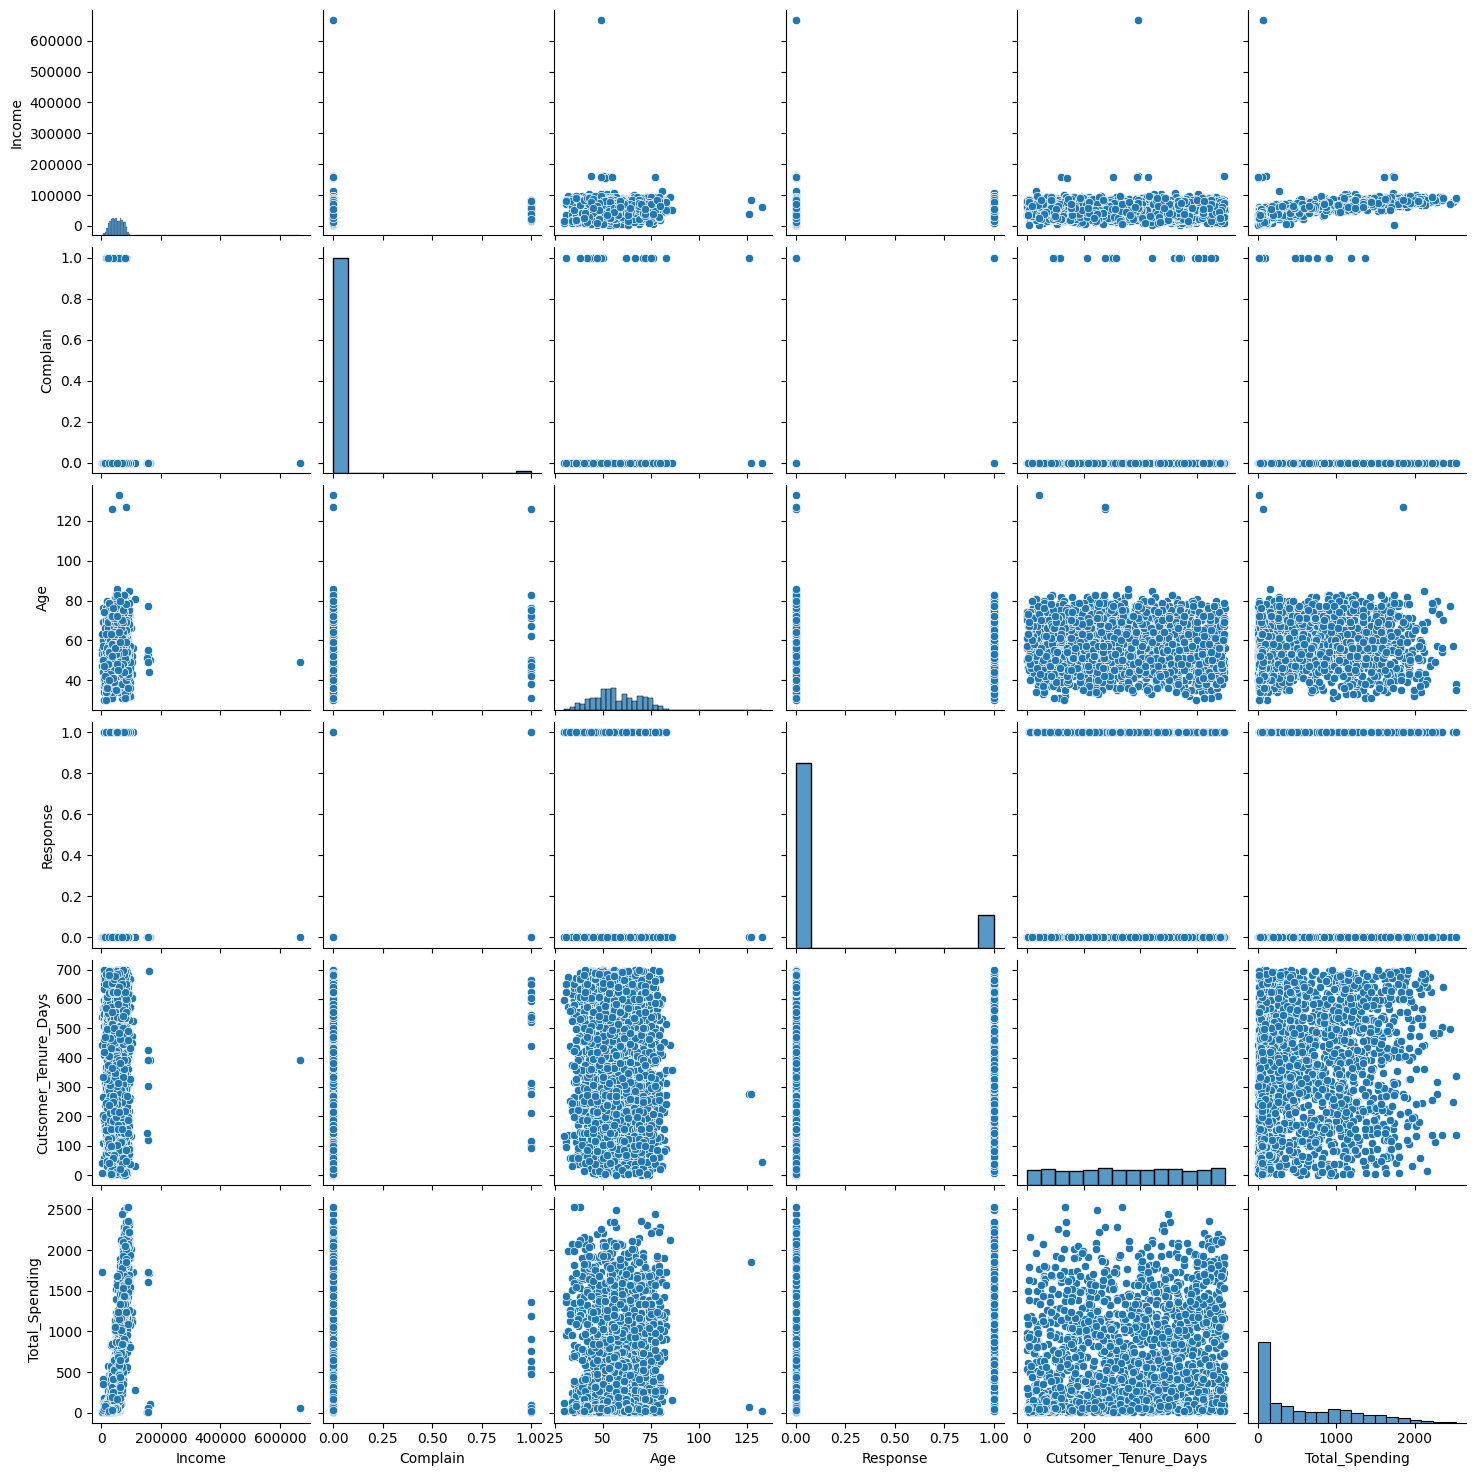

In [60]:
cols=['Income','Complain','Age','Response','Cutsomer_Tenure_Days' ,'Total_Spending', 'Living_With', 'Education']
sns.pairplot(df_cleaned[cols])

In [61]:
#REMOVING OUTLIERS
df_cleaned=df_cleaned[(df_cleaned['Age']<90)]
df_cleaned=df_cleaned[(df_cleaned['Income']<600000)]
print(len(df_cleaned))
df_cleaned.info()



2236
<class 'pandas.core.frame.DataFrame'>
Index: 2236 entries, 0 to 2239
Data columns (total 15 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Education             2236 non-null   object 
 1   Income                2236 non-null   float64
 2   Recency               2236 non-null   int64  
 3   NumDealsPurchases     2236 non-null   int64  
 4   NumWebPurchases       2236 non-null   int64  
 5   NumCatalogPurchases   2236 non-null   int64  
 6   NumStorePurchases     2236 non-null   int64  
 7   NumWebVisitsMonth     2236 non-null   int64  
 8   Complain              2236 non-null   int64  
 9   Response              2236 non-null   int64  
 10  Age                   2236 non-null   int64  
 11  Cutsomer_Tenure_Days  2236 non-null   int64  
 12  Total_Spending        2236 non-null   int64  
 13  Childres              2236 non-null   int64  
 14  Living_With           2236 non-null   object 
dtypes: float64(1), int64(

# HeatMap

<Axes: >

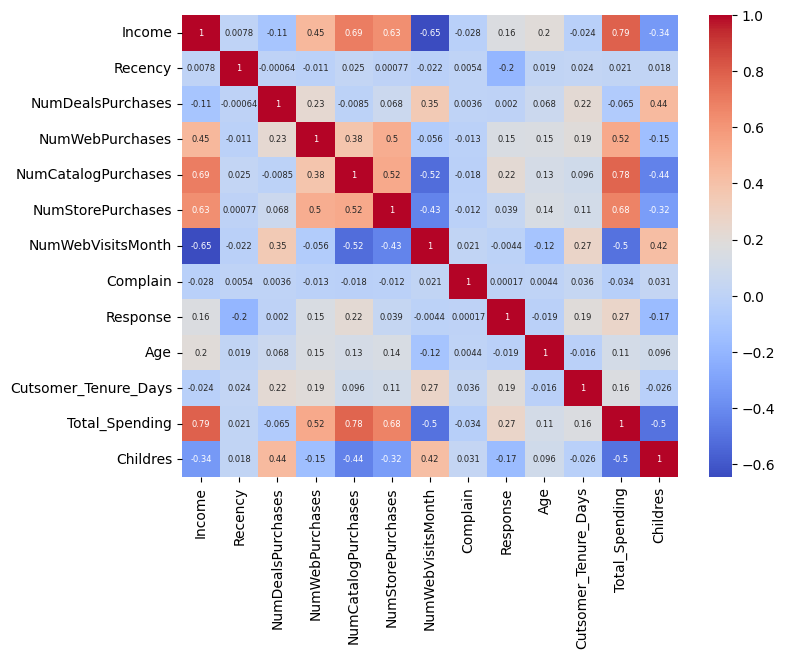

In [62]:
corr=df_cleaned.corr(numeric_only=True)
plt.figure(figsize=(8,6))
sns.heatmap(
    corr,
    annot=True,
    cmap='coolwarm',
    annot_kws={'size':6}
)

# One Hot Encoder

In [65]:
from sklearn.preprocessing import OneHotEncoder
ohe= OneHotEncoder()
cols=['Education','Living_With']
encoded=ohe.fit_transform(df_cleaned[cols])
encoded_df=pd.DataFrame(encoded.toarray(),columns=ohe.get_feature_names_out(cols),index=df_cleaned.index)
df_encoded=pd.concat([df_cleaned.drop(columns=cols),encoded_df],axis=1)
df_encoded

,Income,Recency,NumDealsPurchases,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,Complain,Response,Age,Cutsomer_Tenure_Days,Total_Spending,Childres,Education_Graduate,Education_PostGraduate,Education_UnderGraduate,Living_With_Alone,Living_With_Partner
0,58138.0,58,3,8,10,4,7,0,1,69,663,1617,0,1.0,0.0,0.0,1.0,0.0
1,46344.0,38,2,1,1,2,5,0,0,72,113,27,2,1.0,0.0,0.0,1.0,0.0
2,71613.0,26,1,8,2,10,4,0,0,61,312,776,0,1.0,0.0,0.0,0.0,1.0
3,26646.0,26,2,2,0,4,6,0,0,42,139,53,1,1.0,0.0,0.0,0.0,1.0
4,58293.0,94,5,5,3,6,5,0,0,45,161,422,1,0.0,1.0,0.0,0.0,1.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2235,61223.0,46,2,9,3,4,5,0,0,59,381,1341,1,1.0,0.0,0.0,0.0,1.0
2236,64014.0,56,7,8,2,5,7,0,0,80,19,444,3,0.0,1.0,0.0,0.0,1.0
2237,56981.0,91,1,2,3,13,6,0,0,45,155,1241,0,1.0,0.0,0.0,1.0,0.0
2238,69245.0,8,2,6,5,10,3,0,0,70,156,843,1,0.0,1.0,0.0,0.0,1.0


# Scaling 

In [68]:
from sklearn.preprocessing  import StandardScaler
x=df_encoded
scaler=StandardScaler()
x_scaled=scaler.fit_transform(x)
x_scaled

array([[ 0.28894655,  0.30685572,  0.34873831, ..., -0.35877969,
         1.3476353 , -1.3476353 ],
       [-0.262003  , -0.38397129, -0.16869955, ..., -0.35877969,
         1.3476353 , -1.3476353 ],
       [ 0.91842301, -0.7984675 , -0.68613742, ..., -0.35877969,
        -0.74204052,  0.74204052],
       ...,
       [ 0.234898  ,  1.44672029, -0.68613742, ..., -0.35877969,
         1.3476353 , -1.3476353 ],
       [ 0.80780332, -1.42021181, -0.16869955, ..., -0.35877969,
        -0.74204052,  0.74204052],
       [ 0.04280841, -0.31488859,  0.34873831, ..., -0.35877969,
        -0.74204052,  0.74204052]], shape=(2236, 18))

# Visualizing

variance : [0.23163158 0.11385454]


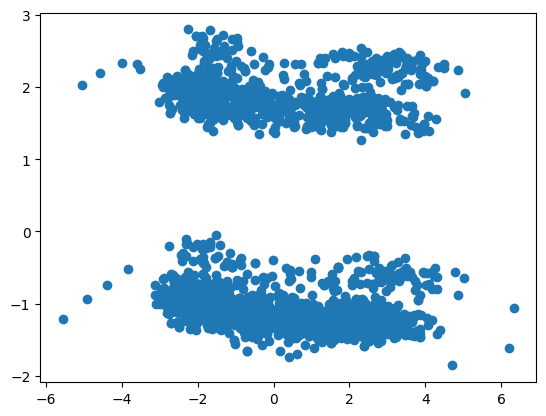

In [73]:
from sklearn.decomposition import PCA
pca=PCA(n_components=2)
x_pca=pca.fit_transform(x_scaled)
plt.scatter(x_pca[:,0], x_pca[:,1])
print("variance :", pca.explained_variance_ratio_)

variance : [0.23163158 0.11385454 0.10405815]


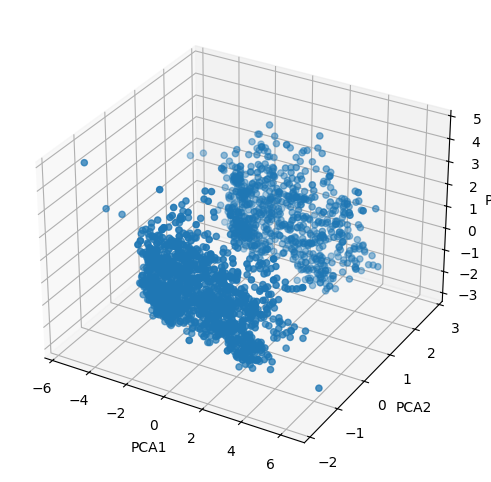

In [77]:
pca=PCA(n_components=3)
x_pca=pca.fit_transform(x_scaled)
fig=plt.figure(figsize=(8,6))
ax=fig.add_subplot(111, projection='3d')
ax.scatter(x_pca[:,0], x_pca[:,1], x_pca[:,2])
ax.set_xlabel('PCA1')
ax.set_ylabel('PCA2')
ax.set_zlabel('PCA3')
print("variance :", pca.explained_variance_ratio_)

# Finding Kmeans value using Elbow Method

Best K value : 4


Text(0, 0.5, 'wcss')

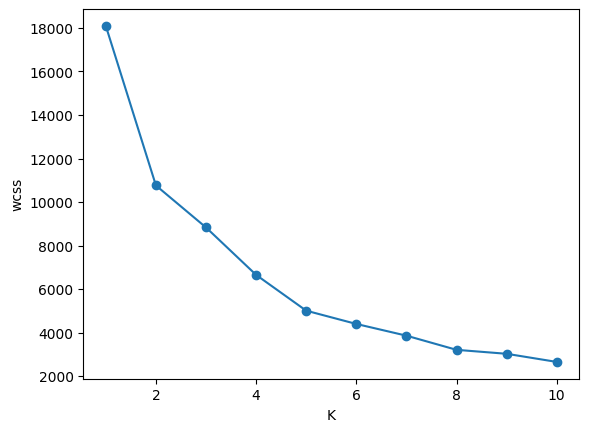

In [87]:
from sklearn.cluster import KMeans
from kneed import KneeLocator

wcss=[]
for k in range(1, 11):
    model=KMeans(n_clusters=k, random_state=42)
    model.fit_predict(x_pca)
    wcss.append(model.inertia_)

optimal_k=KneeLocator(range(1,11), wcss, curve='convex', direction='decreasing')
print('Best K value :' , optimal_k.elbow)

plt.plot(range(1,11), wcss, marker='o')
plt.xlabel('K')
plt.ylabel('wcss')

# Using Silhoutte Method

Text(0, 0.5, 'Score')

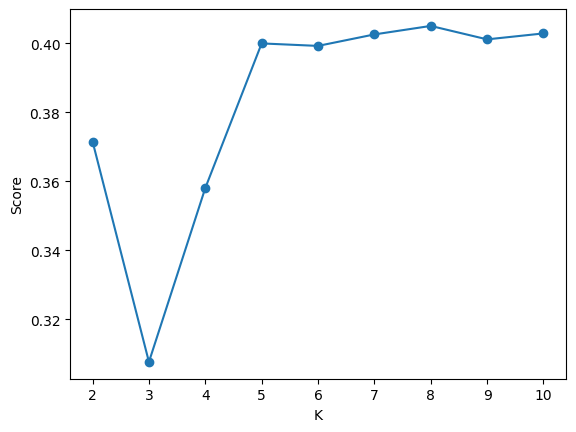

In [92]:
from sklearn.metrics import silhouette_score
scores=[]
for k in range(2, 11):
    model=KMeans(n_clusters=k, random_state=42)
    labels=model.fit_predict(x_pca)
    score=silhouette_score(x_pca, labels)
    scores.append(score)
plt.plot(range(2,11), scores, marker='o')
plt.xlabel('K')
plt.ylabel('Score')

# Merging 2 Plot

Text(0, 0.5, 'score')

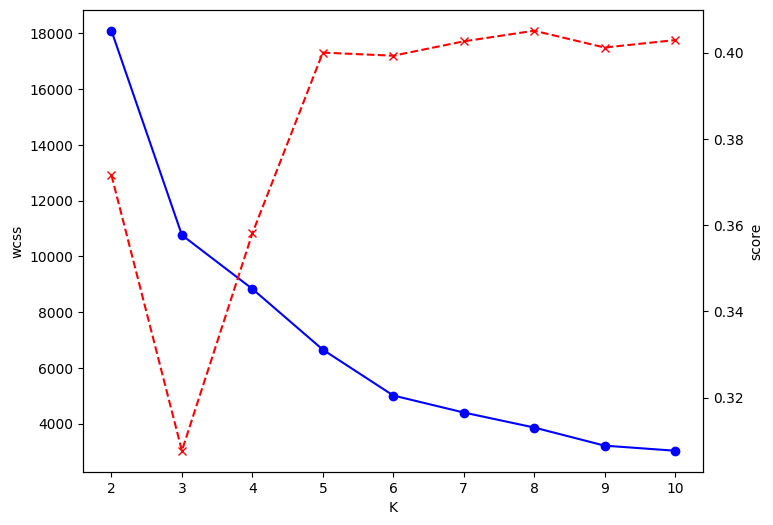

In [96]:

k_range=range(2,11)

fig, ax1=plt.subplots(figsize=(8,6))
ax1.plot(k_range, wcss[:len(k_range)], marker='o', color='blue')
ax1.set_xlabel('K')
ax1.set_ylabel('wcss')

ax2=ax1.twinx()
ax2.plot(k_range, scores[:len(k_range)], marker='x',color='red', linestyle='--')
ax2.set_ylabel('score')

# Clustering 

Text(0.5, 0, 'PCA3')

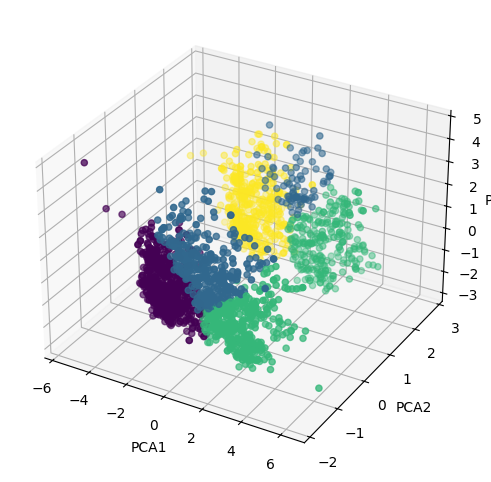

In [109]:

model=KMeans(n_clusters=4, random_state=42)
kmeans_labels=model.fit_predict(x_pca)

fig=plt.figure(figsize=(8,6))
ax=fig.add_subplot(111,projection='3d')
ax.scatter(x_pca[:,0], x_pca[:,1], x_pca[:,2], c=kmeans_labels)
ax.set_xlabel('PCA1')
ax.set_ylabel('PCA2')
ax.set_zlabel('PCA3')


Text(0.5, 0, 'PCA3')

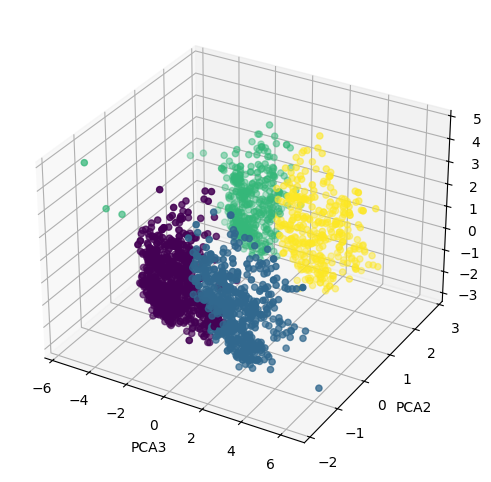

In [113]:
from sklearn.cluster import AgglomerativeClustering
model= AgglomerativeClustering(n_clusters=4, linkage='ward')
agg_labels=model.fit_predict(x_pca)
fig=plt.figure(figsize=(8,6))
ax=fig.add_subplot(111, projection='3d')
ax.scatter(x_pca[:,0], x_pca[:,1], x_pca[:,2], c=agg_labels)
ax.set_xlabel("PCA1")
ax.set_ylabel("PCA2")
ax.set_xlabel("PCA3")



# Charectization of Clusters

In [136]:
x['clusters']=agg_labels
pal=['red', 'blue', 'yellow', 'green']

<Axes: xlabel='clusters', ylabel='count'>

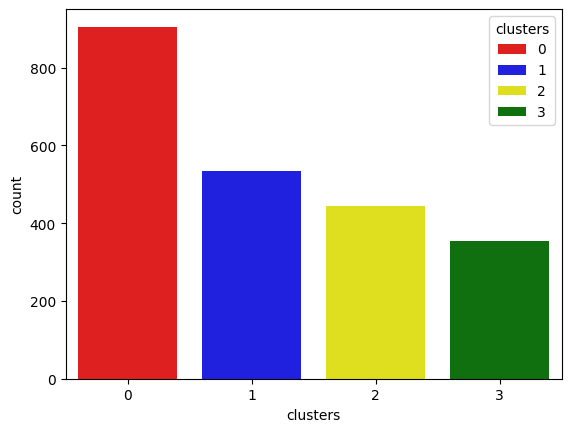

In [137]:
sns.countplot(x=x['clusters'], palette=pal, hue=x['clusters'])

<Axes: xlabel='Total_Spending', ylabel='Income'>

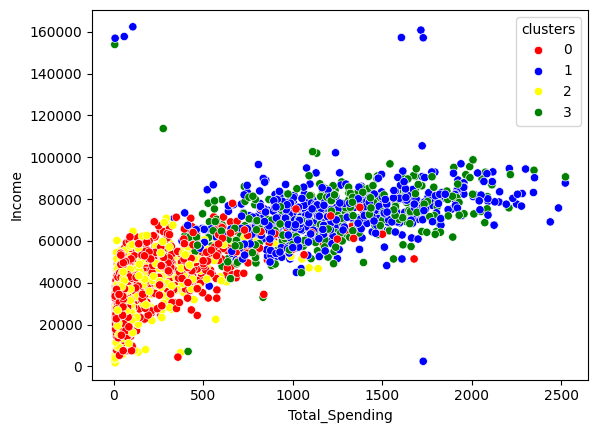

In [138]:
sns.scatterplot( x=x['Total_Spending'], y=x['Income'],hue=x['clusters'], palette=pal)

# clustering Summary 

In [140]:
cluster_summary=x.groupby('clusters').mean()
print(cluster_summary)

                Income    Recency  NumDealsPurchases  NumWebPurchases  \
clusters                                                                
0         39680.580110  48.914917           2.594475         3.153591   
1         72808.445693  49.202247           1.958801         5.687266   
2         36960.143018  48.319820           2.594595         2.713964   
3         70722.681303  50.504249           1.855524         5.790368   

          NumCatalogPurchases  NumStorePurchases  NumWebVisitsMonth  Complain  \
clusters                                                                        
0                    0.969061           4.143646           6.307182  0.011050   
1                    5.498127           8.659176           3.580524  0.005618   
2                    0.837838           3.623874           6.659910  0.011261   
3                    5.014164           8.430595           3.728045  0.005666   

          Response        Age  Cutsomer_Tenure_Days  Total_Spending  Child

#cluster 0 - family customer and low spendings,  can suggest coupons deals


#cluster 1 - Elite customer with partner, can offer loyalty deals


#cluster 2 - low spending cutsomer without partner and low income , can affordable and more deals


#cluster 3 - Elite customr without family and response is good  , can offer primium deals and need to prioritize for revenue.
